<a href="https://colab.research.google.com/github/annamtrinh/Roth-IRA-Monte-Carlo-Simulation/blob/main/Roth_IRA_Monte_Carlo_Simulator.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [85]:

# Install financial data library
!pip install yfinance -q

# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import yfinance as yf

print("ROTH IRA SIM")

ROTH IRA SIM


In [86]:
#Current ETF Holdings
tickers = [
    "VOO",
    "VOOG",
    "VXUS",
    "SPMO",
    "SMH",
    "QQQM"
]
print("Current ROTH IRA Portfolio Holdings")
print(tickers)
print("Number of ETFS:", len(tickers))

Current ROTH IRA Portfolio Holdings
['VOO', 'VOOG', 'VXUS', 'SPMO', 'SMH', 'QQQM']
Number of ETFS: 6


In [87]:
#The last 5 years of data of my etfs
data = yf.download(
    tickers,
    period = "5y",
    interval = "1d",
    auto_adjust = True,
    progress = False
)
#Get the adjusted closing prices
prices = data["Close"]

#Print out the first few rows of data
print(prices.head())

# Get data from January 1, 2021, to December 31, 2023
filtered_prices = prices.loc["2021-01-01":"2023-12-31"]

print(filtered_prices.head())

#Get data from all 5 years
#with pd.option_context('display.max_rows', None):
   # print(prices)


Ticker            QQQM         SMH       SPMO         VOO       VOOG  \
Date                                                                   
2021-11-15  157.158447  145.879456  61.725994  400.653809  47.618923   
2021-11-16  158.301743  147.771469  61.927097  402.182800  48.023666   
2021-11-17  158.350220  146.893372  61.597572  401.213226  47.965855   
2021-11-18  159.977997  150.507614  61.641968  402.602356  48.433224   
2021-11-19  160.908157  151.458496  61.442738  401.847168  48.659698   

Ticker           VXUS  
Date                   
2021-11-15  56.553017  
2021-11-16  56.432884  
2021-11-17  56.304157  
2021-11-18  56.149677  
2021-11-19  55.789257  
Ticker            QQQM         SMH       SPMO         VOO       VOOG  \
Date                                                                   
2021-11-15  157.158447  145.879456  61.725994  400.653809  47.618923   
2021-11-16  158.301743  147.771469  61.927097  402.182800  48.023666   
2021-11-17  158.350220  146.893372  61.

In [88]:
#\n makes the print go down a line
#Finds the dimensions of the data set (Rows and columns)
print("Dimensions of the data set")
print(prices.shape)

#Finds the column names aka the etfs
print("\nColumn names:")
print(prices.columns)

#Finds number of missing values (ex - If a certain day had no value for QQM it would say QQM 1)
print("\nMissing Values")
print(prices.isna().sum())

#Find info of the dataset
print("\nDataset Information:")
prices.info()




Dimensions of the data set
(1255, 6)

Column names:
Index(['QQQM', 'SMH', 'SPMO', 'VOO', 'VOOG', 'VXUS'], dtype='object', name='Ticker')

Missing Values
Ticker
QQQM    0
SMH     0
SPMO    0
VOO     0
VOOG    0
VXUS    0
dtype: int64

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 1255 entries, 2021-11-15 to 2026-11-13
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   QQQM    1255 non-null   float64
 1   SMH     1255 non-null   float64
 2   SPMO    1255 non-null   float64
 3   VOO     1255 non-null   float64
 4   VOOG    1255 non-null   float64
 5   VXUS    1255 non-null   float64
dtypes: float64(6)
memory usage: 100.9 KB


In [89]:
#Remove the dates where an ETF has a missing price
prices = prices.dropna()

#Find the daily percentage returns (Daily return = (Todays price-yesterdays price)/yesterdays price)
daily_returns = prices.pct_change().dropna()

#This prints the first five rows
print(daily_returns.head())

Ticker          QQQM       SMH      SPMO       VOO      VOOG      VXUS
Date                                                                  
2021-11-16  0.007275  0.012970  0.003258  0.003816  0.008500 -0.002124
2021-11-17  0.000306 -0.005942 -0.005321 -0.002411 -0.001204 -0.002281
2021-11-18  0.010280  0.024605  0.000721  0.003462  0.009744 -0.002744
2021-11-19  0.005814  0.006318 -0.003232 -0.001876  0.004676 -0.006419
2021-11-22 -0.011381 -0.015087  0.001644 -0.002645 -0.010331 -0.006307


In [90]:
average_returns = daily_returns.mean()

print("Average Daily Returns:")
print(average_returns)

Average Daily Returns:
Ticker
QQQM    0.000567
SMH     0.001243
SPMO    0.000700
VOO     0.000495
VOOG    0.000505
VXUS    0.000357
dtype: float64


In [91]:
#.std is standard deviation
volatility = daily_returns.std()

#Gives the volatility of each etf (How much they fluctuate in price)
print("Daily Volatility:")
print(volatility)


Daily Volatility:
Ticker
QQQM    0.014617
SMH     0.023734
SPMO    0.013520
VOO     0.010766
VOOG    0.013758
VXUS    0.010422
dtype: float64


In [92]:
summary = pd.DataFrame({
    "Average Daily Return": average_returns,
    "Daily Volatility":volatility
})
print(summary)

        Average Daily Return  Daily Volatility
Ticker                                        
QQQM                0.000567          0.014617
SMH                 0.001243          0.023734
SPMO                0.000700          0.013520
VOO                 0.000495          0.010766
VOOG                0.000505          0.013758
VXUS                0.000357          0.010422


In [93]:
#Find the correlation between the 6 etfs
#Correlation describes strength and direction of relationship between two things
#in this case 2 etfs
correlation_matrix = daily_returns.corr()

#display the results rounded to 2 decimal places
print(correlation_matrix.round(2))

Ticker  QQQM   SMH  SPMO   VOO  VOOG  VXUS
Ticker                                    
QQQM    1.00  0.90  0.84  0.95  0.98  0.76
SMH     0.90  1.00  0.82  0.81  0.86  0.72
SPMO    0.84  0.82  1.00  0.85  0.86  0.73
VOO     0.95  0.81  0.85  1.00  0.97  0.81
VOOG    0.98  0.86  0.86  0.97  1.00  0.76
VXUS    0.76  0.72  0.73  0.81  0.76  1.00


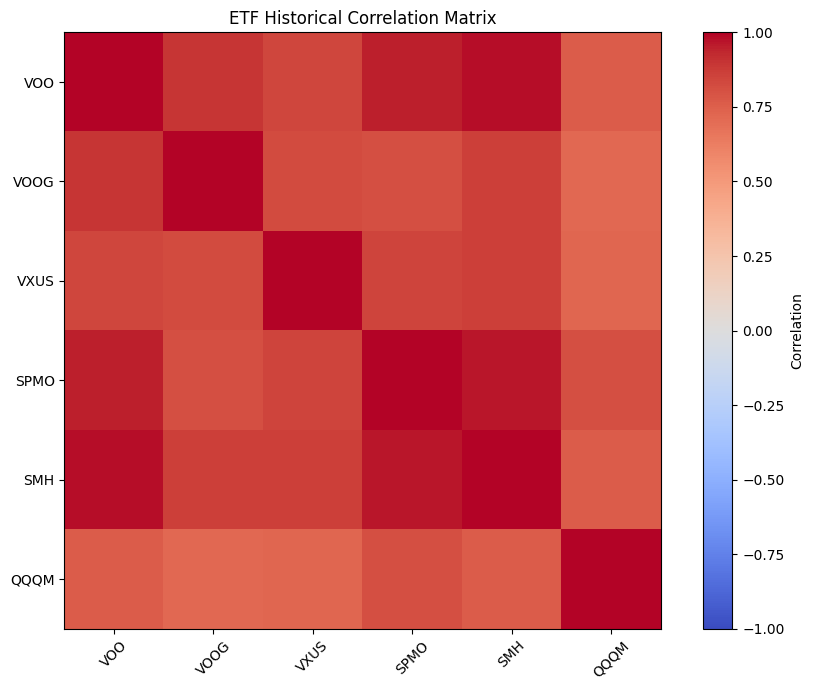

In [94]:
correlation_matrix = daily_returns.corr()

#Creates a blank picture frame that is 9x7
plt.figure(figsize=(9, 7))

#Draws a grid of colored squares where red is the etfs move together well while blue means they differ
#Locked between -1 and 1
plt.imshow(correlation_matrix, cmap="coolwarm", vmin=-1, vmax=1)


#Color legend
plt.colorbar(label="Correlation")

#Label bottom legend
plt.xticks(
    range(len(tickers)),
    tickers,
    rotation=45
)

#Side axis labels
plt.yticks(
    range(len(tickers)),
    tickers
)
#title
plt.title("ETF Historical Correlation Matrix")

plt.tight_layout()
plt.show()

In [95]:
# Weight of each ETF in portfolio as a percentage
weight = pd.Series({
    "QQQM": 15.4,
    "SMH": 7.4,
    "SPMO": 3.9,
    "VOO": 38.4,
    "VOOG": 15.0,
    "VXUS": 20.0
})

# Convert percentages into decimals
weight = weight / 100

# Match the order of the ETF data
weight = weight.reindex(daily_returns.columns)

# Normalize to add up to 100%
weight = weight / weight.sum()

print("Portfolio Weights:")
print(weight)

print("\nTotal allocation:", weight.sum())

Portfolio Weights:
Ticker
QQQM    0.153846
SMH     0.073926
SPMO    0.038961
VOO     0.383616
VOOG    0.149850
VXUS    0.199800
dtype: float64

Total allocation: 0.9999999999999999


In [96]:
#Calculate the growth of $1 being invested in each etf
growth_assets = (1 + daily_returns).cumprod()

#Combines the growth of etfs using the starting allocations
portfolio_value = growth_assets.mul(weight, axis = 1).sum(axis = 1)

#Calculate portfolio daily returns (.Dropna() drops the missing values)
portfolio_returns = portfolio_value.pct_change().dropna()

print("Historical Portfolio Returns:")
print(portfolio_returns.head()) #.head() finds for first 5 rows


Historical Portfolio Returns:
Date
2021-11-17   -0.002161
2021-11-18    0.005695
2021-11-19   -0.000017
2021-11-22   -0.006676
2021-11-23   -0.001339
dtype: float64


In [97]:
portfolio_average_return = portfolio_returns.mean()
portfolio_volatility = portfolio_returns.std()

print("Average Daily Portfolio Return:",
      round(portfolio_average_return, 5))

print("Daily Portfolio Volatility:",
      round(portfolio_volatility, 5))

Average Daily Portfolio Return: 0.00055
Daily Portfolio Volatility: 0.01238


In [98]:
num_simulations = 10000

#252 trading days in a year
trading_days = 252

#random seed (makes it reproducible)
rng = np.random.default_rng(18)

print("Number of simulations:",
      num_simulations)
print("Trading days per simulation", trading_days)

Number of simulations: 10000
Trading days per simulation 252


In [99]:
#Historical Average daily returns
#.to_numpy convert pandas (series) to raw numpy array
mean_returns = daily_returns.mean().to_numpy()

#Hisotrical Covariance matrix
#Covariance matrix gives info about how two etfs move together
#Covariance incorporates each individual volatility
covariance_matrix = daily_returns.cov().to_numpy()

print("Mean Returns:", mean_returns)

print("\nCovariance Matrix:", covariance_matrix)


Mean Returns: [0.00056721 0.00124273 0.00069951 0.00049535 0.00050539 0.00035674]

Covariance Matrix: [[2.13646501e-04 3.10628852e-04 1.65748346e-04 1.49714267e-04
  1.96809281e-04 1.16167525e-04]
 [3.10628852e-04 5.63325727e-04 2.63843435e-04 2.07612490e-04
  2.81713785e-04 1.77591584e-04]
 [1.65748346e-04 2.63843435e-04 1.82790597e-04 1.23540044e-04
  1.60314126e-04 1.02176200e-04]
 [1.49714267e-04 2.07612490e-04 1.23540044e-04 1.15912413e-04
  1.43174679e-04 9.08551822e-05]
 [1.96809281e-04 2.81713785e-04 1.60314126e-04 1.43174679e-04
  1.89283313e-04 1.09472690e-04]
 [1.16167525e-04 1.77591584e-04 1.02176200e-04 9.08551822e-05
  1.09472690e-04 1.08608604e-04]]


In [100]:
#Simulate random daily returns for all 6 etfs
#rng.multivariate_normal - generate random numbers following gaussian distribution
#Bell Curve
simulate_daily_returns = rng.multivariate_normal(
    mean=mean_returns,
    cov=covariance_matrix,
    size=(num_simulations, trading_days)
)

print("Simulated Dimensions:", simulate_daily_returns.shape)
#10000, 252, 6 stand for 10,000 simulations 252 trading days and 6 ETFS

Simulated Dimensions: (10000, 252, 6)


In [101]:
growth_assets = np.cumprod(
    1 + simulate_daily_returns,
    axis=1
)
print("Asset Growth Dimensions", growth_assets.shape)

Asset Growth Dimensions (10000, 252, 6)


In [102]:
#match up weights with ETFS
weight = weight.reindex(daily_returns.columns).to_numpy()

#Calculates combined portfolio value for each of the simulations
portfolio_paths = np.sum(
    growth_assets * weight.reshape(1, 1, -1),
    axis=2
)

print("Portfolio Simulation Dimensions:", portfolio_paths.shape)


Portfolio Simulation Dimensions: (10000, 252)


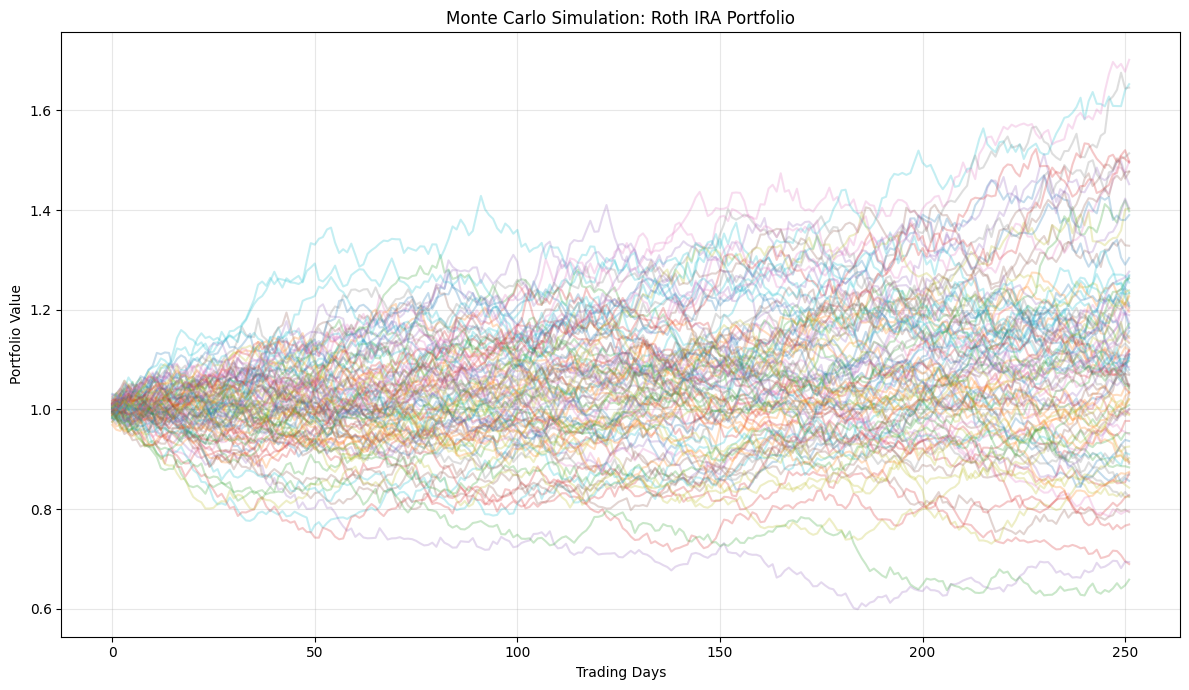

In [103]:

portfolio_paths = np.sum(
    growth_assets * weight.reshape(1, 1, -1),
    axis=2
)
plt.figure(figsize=(12,7))

for i in range(100):
  plt.plot(portfolio_paths[i], alpha = 0.25)

plt.title("Monte Carlo Simulation: Roth IRA Portfolio")
plt.xlabel("Trading Days")
plt.ylabel("Portfolio Value")
plt.grid(True, alpha=0.3)#Adds background grid to make values more readable

plt.tight_layout()#adjusts spacing and margins
plt.show()



In [104]:
final_values = portfolio_paths[:, -1]

print("Number of final outcomes", len(final_values))
print("\nFirst 10 ending values:")
print(final_values[:10])

Number of final outcomes 10000

First 10 ending values:
[0.93664981 1.11845374 1.09718789 0.87144238 1.17430419 1.3283607
 1.49748261 1.2070995  0.90230659 1.23586121]


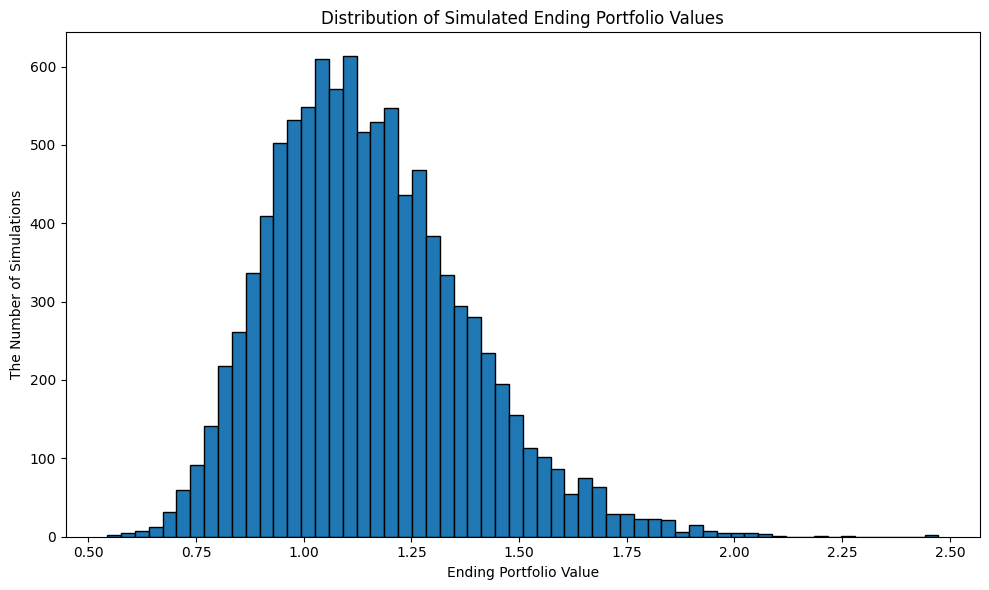

In [105]:
plt.figure(figsize = (10, 6))

plt.hist(final_values, bins=60, edgecolor = "black")

plt.title("Distribution of Simulated Ending Portfolio Values")
plt.xlabel("Ending Portfolio Value")
plt.ylabel("The Number of Simulations")

plt.tight_layout()
plt.show()


In [106]:
#5th Percentile means 5% of outcomes below a certain value
#Median, Half of outcomes at or below the value
#95th Percentile, 95% of outcomes were at or below this value
p5, median, p95 = np.percentile(
    final_values,
    [5, 50, 95]
)
print("5th Percentile:", p5)
print("Median:", median)
print("95th Percentile", p95)


5th Percentile: 0.8240230834652157
Median: 1.124974261414052
95th Percentile 1.558738898990932


In [107]:
prob_loss = np.mean(final_values < 1)

print(f"Probability of ending below starting value: {prob_loss:.2%}")


Probability of ending below starting value: 27.31%


In [108]:
results_summary = pd.DataFrame({
    "Metric":[
        "5th Percentile",
        "Median End Value",
        "95th Percentile",
        "Average Ending Value",
        "Probability of Loss"
    ],
    "Value":[
        p5,
        median,
        p95,
        np.mean(final_values),
        prob_loss
    ]
})

print(results_summary)

                 Metric     Value
0        5th Percentile  0.824023
1      Median End Value  1.124974
2       95th Percentile  1.558739
3  Average Ending Value  1.150726
4   Probability of Loss  0.273100
